In [1]:
import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision import datasets

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch:", torch.__version__)
print("device:", device)

torch: 2.11.0+cu128
device: cuda


In [2]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

DATA_SPLIT_SEED = 42
set_seed(DATA_SPLIT_SEED)

In [3]:
CACHE_PATH = "cifar10_raw.npz"

def load_cifar10(cache_path=CACHE_PATH, root="./data"):
    if os.path.exists(cache_path):
        d = np.load(cache_path)
        return d["xtr"], d["ytr"], d["xte"], d["yte"]
    tr = datasets.CIFAR10(root, train=True, download=True)
    te = datasets.CIFAR10(root, train=False, download=True)
    xtr, ytr = tr.data, np.array(tr.targets)
    xte, yte = te.data, np.array(te.targets)
    np.savez_compressed(cache_path, xtr=xtr, ytr=ytr, xte=xte, yte=yte)
    return xtr, ytr, xte, yte

x_train_full, y_train_full, x_clean_test, y_clean_test = load_cifar10()

print("full train:", x_train_full.shape, y_train_full.shape)
print("clean test:", x_clean_test.shape, y_clean_test.shape)
print("dtype:", x_train_full.dtype)

100%|██████████| 170M/170M [26:36<00:00, 107kB/s]  


full train: (50000, 32, 32, 3) (50000,)
clean test: (10000, 32, 32, 3) (10000,)
dtype: uint8


In [4]:
CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

rng = np.random.RandomState(DATA_SPLIT_SEED)
small_idx = np.concatenate([
    rng.choice(np.where(y_train_full == c)[0], size=50, replace=False)
    for c in range(10)
])

x_small = x_train_full[small_idx]
y_small = y_train_full[small_idx]

print("train_small:", x_small.shape)
print("per-class counts:", np.bincount(y_small))

train_small: (500, 32, 32, 3)
per-class counts: [50 50 50 50 50 50 50 50 50 50]


In [6]:
split_rng = np.random.RandomState(DATA_SPLIT_SEED + 1)
tr_idx, va_idx = [], []

for c in range(10):
    ci = split_rng.permutation(np.where(y_small == c)[0])
    tr_idx.extend(ci[:40])
    va_idx.extend(ci[40:])

tr_idx, va_idx = np.array(tr_idx), np.array(va_idx)

x_tr, y_tr = x_small[tr_idx], y_small[tr_idx]
x_va, y_va = x_small[va_idx], y_small[va_idx]

print("train:", x_tr.shape, np.bincount(y_tr))
print("val:  ", x_va.shape, np.bincount(y_va))
print("overlap between train and val:", len(set(tr_idx) & set(va_idx)))

train: (400, 32, 32, 3) [40 40 40 40 40 40 40 40 40 40]
val:   (100, 32, 32, 3) [10 10 10 10 10 10 10 10 10 10]
overlap between train and val: 0


In [7]:
def to_tensor(x_uint8):
    return torch.from_numpy(x_uint8).permute(0, 3, 1, 2).float().div(255.0)

X_tr = to_tensor(x_tr).to(device)
Y_tr = torch.from_numpy(y_tr).long().to(device)
X_va = to_tensor(x_va).to(device)
Y_va = torch.from_numpy(y_va).long().to(device)
X_clean = to_tensor(x_clean_test).to(device)
Y_clean = torch.from_numpy(y_clean_test).long().to(device)

print("X_tr:", X_tr.shape, X_tr.min().item(), X_tr.max().item())
print("X_va:", X_va.shape)
print("X_clean:", X_clean.shape)

X_tr: torch.Size([400, 3, 32, 32]) 0.0 1.0
X_va: torch.Size([100, 3, 32, 32])
X_clean: torch.Size([10000, 3, 32, 32])


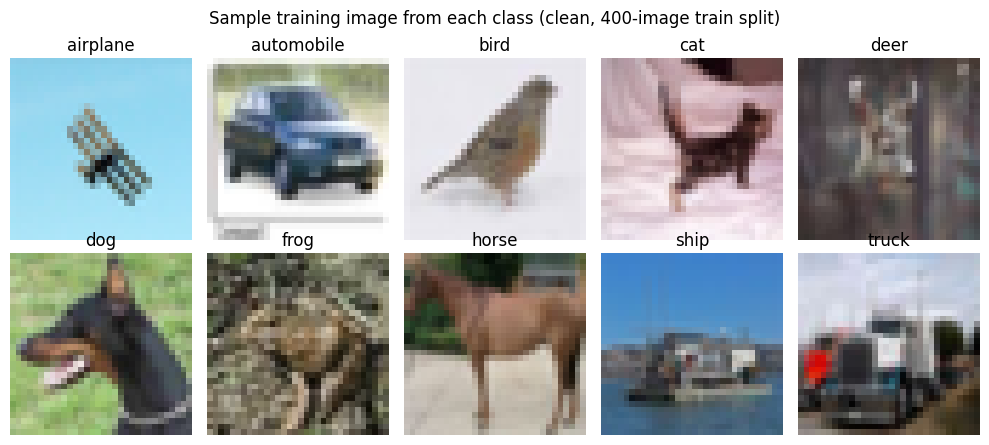

In [8]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for c, ax in enumerate(axes.ravel()):
    i = np.where(y_tr == c)[0][0]
    ax.imshow(x_tr[i])
    ax.set_title(CLASS_NAMES[c])
    ax.axis("off")
fig.suptitle("Sample training image from each class (clean, 400-image train split)")
plt.tight_layout()
plt.show()

In [9]:
#corruption functions
import math

def rotate_batch(x, max_deg, gen):
    n = x.shape[0]
    ang = (torch.rand(n, generator=gen, device=x.device) * 2 - 1) * max_deg
    ang = ang * math.pi / 180.0
    cos, sin = torch.cos(ang), torch.sin(ang)
    theta = torch.zeros(n, 2, 3, device=x.device)
    theta[:, 0, 0], theta[:, 0, 1] = cos, -sin
    theta[:, 1, 0], theta[:, 1, 1] = sin, cos
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    return F.grid_sample(x, grid, padding_mode="zeros", align_corners=False)

def brightness_contrast(x, lo, hi, gen):
    n = x.shape[0]
    b = torch.rand(n, 1, 1, 1, generator=gen, device=x.device) * (hi - lo) + lo
    c = torch.rand(n, 1, 1, 1, generator=gen, device=x.device) * (hi - lo) + lo
    mean = x.mean(dim=(1, 2, 3), keepdim=True)
    x = (x - mean) * c + mean
    x = x * b
    return x.clamp(0, 1)

def occlude(x, area_frac, gen):
    n, _, h, w = x.shape
    side = int(round(math.sqrt(area_frac * h * w)))
    out = x.clone()
    ys = torch.randint(0, h - side + 1, (n,), generator=gen, device=x.device)
    xs = torch.randint(0, w - side + 1, (n,), generator=gen, device=x.device)
    for i in range(n):
        out[i, :, ys[i]:ys[i] + side, xs[i]:xs[i] + side] = 0.0
    return out

def hidden_corruption(x, gen):
    n = x.shape[0]
    out = x.clone()
    mode = torch.randint(0, 3, (n,), generator=gen, device=x.device)
    perms = torch.tensor([[2, 1, 0], [1, 2, 0], [0, 2, 1]], device=x.device)
    pick = torch.randint(0, 3, (n,), generator=gen, device=x.device)
    for i in range(n):
        if mode[i] == 1:
            out[i] = out[i][perms[pick[i]]]
        elif mode[i] == 2:
            g = (0.299 * out[i, 0] + 0.587 * out[i, 1] + 0.114 * out[i, 2])
            out[i] = g.unsqueeze(0).repeat(3, 1, 1)
    return out

In [10]:
# shifted_test    
def make_shifted(x, seed=123):
    gen = torch.Generator(device=x.device)
    gen.manual_seed(seed)
    x = rotate_batch(x, 25.0, gen)
    x = brightness_contrast(x, 0.5, 1.5, gen)
    x = hidden_corruption(x, gen)
    x = occlude(x, 0.25, gen)
    return x

X_shifted = make_shifted(X_clean)
Y_shifted = Y_clean.clone()

X_shifted_again = make_shifted(X_clean)
print("X_shifted:", X_shifted.shape, X_shifted.min().item(), X_shifted.max().item())
print("same result on re-run:", torch.equal(X_shifted, X_shifted_again))

X_shifted: torch.Size([10000, 3, 32, 32]) 0.0 1.0
same result on re-run: True


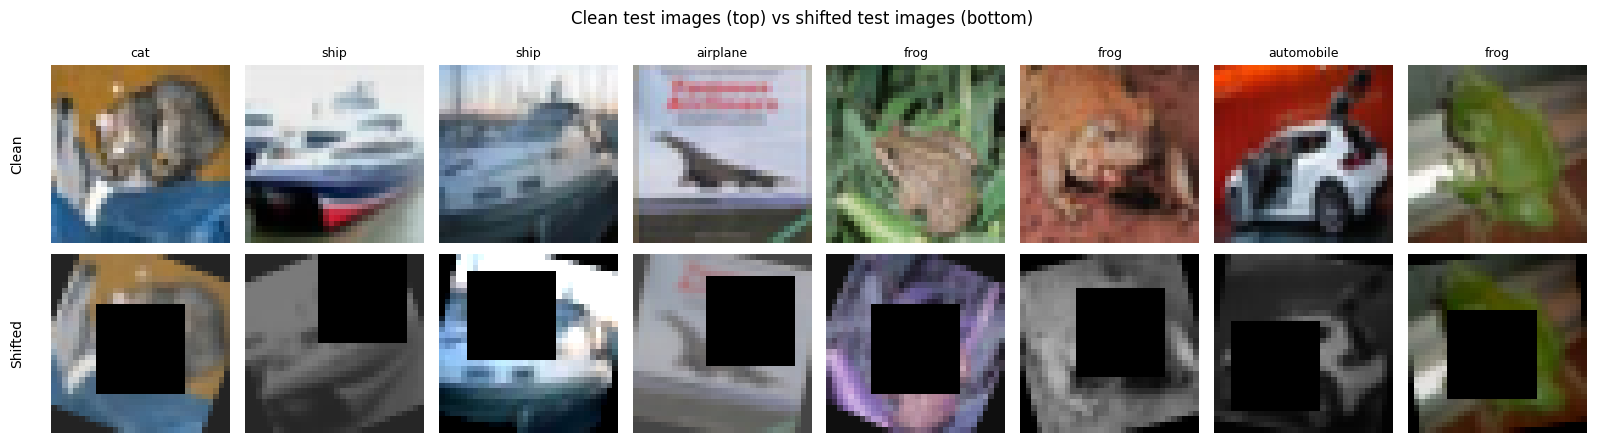

In [11]:
def show_pair(Xa, Xb, labels, n=8, title_a="Clean", title_b="Shifted"):
    fig, axes = plt.subplots(2, n, figsize=(2 * n, 4.6))
    for j in range(n):
        axes[0, j].imshow(Xa[j].permute(1, 2, 0).cpu().numpy())
        axes[0, j].set_title(CLASS_NAMES[labels[j].item()], fontsize=9)
        axes[0, j].axis("off")
        axes[1, j].imshow(Xb[j].permute(1, 2, 0).cpu().numpy())
        axes[1, j].axis("off")
    axes[0, 0].text(-0.15, 0.5, title_a, transform=axes[0, 0].transAxes, rotation=90, va="center", ha="right")
    axes[1, 0].text(-0.15, 0.5, title_b, transform=axes[1, 0].transAxes, rotation=90, va="center", ha="right")
    fig.suptitle("Clean test images (top) vs shifted test images (bottom)")
    plt.tight_layout()
    plt.show()

show_pair(X_clean, X_shifted, Y_clean, n=8)

In [12]:
#incpetion block
train_mean = X_tr.mean(dim=(0, 2, 3)).view(1, 3, 1, 1)
train_std = X_tr.std(dim=(0, 2, 3)).view(1, 3, 1, 1)

print("train mean:", train_mean.flatten().tolist())
print("train std: ", train_std.flatten().tolist())

train mean: [0.4849238991737366, 0.48047465085983276, 0.4542178511619568]
train std:  [0.24849863350391388, 0.24346484243869781, 0.26108318567276]


In [14]:
class ConvBNReLU(nn.Module):
    def __init__(self, cin, cout, k):
        super().__init__()
        self.conv = nn.Conv2d(cin, cout, k, padding=k // 2, bias=False)
        self.bn = nn.BatchNorm2d(cout)

    def forward(self, x):
        return F.relu(self.bn(self.conv(x)))


class InceptionBlock(nn.Module):
    def __init__(self, cin, c1, c3r, c3, c5r, c5, cp):
        super().__init__()
        self.b1 = ConvBNReLU(cin, c1, 1)
        self.b3 = nn.Sequential(ConvBNReLU(cin, c3r, 1), ConvBNReLU(c3r, c3, 3))
        self.b5 = nn.Sequential(ConvBNReLU(cin, c5r, 1), ConvBNReLU(c5r, c5, 5))
        self.bp = nn.Sequential(nn.MaxPool2d(3, stride=1, padding=1), ConvBNReLU(cin, cp, 1))

    def forward(self, x):
        return torch.cat([self.b1(x), self.b3(x), self.b5(x), self.bp(x)], dim=1)


class InceptionNet(nn.Module):
    def __init__(self, mean, std, num_classes=10, dropout=0.4):
        super().__init__()
        self.register_buffer("mean", mean.clone())
        self.register_buffer("std", std.clone())
        self.stem = ConvBNReLU(3, 32, 3)
        self.inc1 = InceptionBlock(32, 16, 16, 24, 8, 8, 8)
        self.inc2 = InceptionBlock(56, 32, 24, 48, 8, 16, 16)
        self.pool = nn.MaxPool2d(2)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(112, num_classes)

    def forward(self, x):
        x = (x - self.mean) / self.std
        x = self.pool(self.stem(x))
        x = self.pool(self.inc1(x))
        x = self.pool(self.inc2(x))
        x = x.mean(dim=(2, 3))
        return self.fc(self.drop(x))

In [15]:
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

model = InceptionNet(train_mean, train_std).to(device)
n_params = count_params(model)
print("trainable parameters:", n_params)
print("within 1,000,000 limit:", n_params <= 1_000_000)

with torch.no_grad():
    out = model(X_tr[:8])
print("output shape:", out.shape)

trainable parameters: 27146
within 1,000,000 limit: True
output shape: torch.Size([8, 10])


In [16]:
# Ye cell kisi bhi dataset par model ki accuracy aur loss nikalta hai (eval mode, batch-wise)

@torch.no_grad()
def evaluate(model, X, Y, batch_size=1000):
    model.eval()
    correct, total_loss = 0, 0.0
    for i in range(0, X.shape[0], batch_size):
        xb, yb = X[i:i + batch_size], Y[i:i + batch_size]
        logits = model(xb)
        total_loss += F.cross_entropy(logits, yb, reduction="sum").item()
        correct += (logits.argmax(1) == yb).sum().item()
    n = X.shape[0]
    return correct / n, total_loss / n

In [17]:
# Ye cell poora training loop hai: har epoch train, train/val metrics record, best-val model save, history return

import copy

def train_model(seed, aug_fn=None, epochs=60, batch_size=64, lr=2e-3,
                weight_decay=5e-4, smoothing=0.0, dropout=0.4):
    set_seed(seed)
    model = InceptionNet(train_mean, train_std, dropout=dropout).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)

    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best = {"val_acc": -1.0, "val_loss": 1e9, "epoch": -1, "state": None}
    n = X_tr.shape[0]

    for ep in range(epochs):
        model.train()
        perm = torch.randperm(n, device=device)
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            xb, yb = X_tr[idx], Y_tr[idx]
            if aug_fn is not None:
                xb = aug_fn(xb)
            loss = F.cross_entropy(model(xb), yb, label_smoothing=smoothing)
            opt.zero_grad()
            loss.backward()
            opt.step()
        sched.step()

        tr_acc, tr_loss = evaluate(model, X_tr, Y_tr)
        va_acc, va_loss = evaluate(model, X_va, Y_va)
        hist["train_loss"].append(tr_loss)
        hist["train_acc"].append(tr_acc)
        hist["val_loss"].append(va_loss)
        hist["val_acc"].append(va_acc)

        if va_acc > best["val_acc"] or (va_acc == best["val_acc"] and va_loss < best["val_loss"]):
            best.update(val_acc=va_acc, val_loss=va_loss, epoch=ep,
                        state=copy.deepcopy(model.state_dict()))

    model.load_state_dict(best["state"])
    return model, hist, best["epoch"]

time (sec): 3.7
best epoch: 35
final train acc: 0.995
best val acc:   0.49


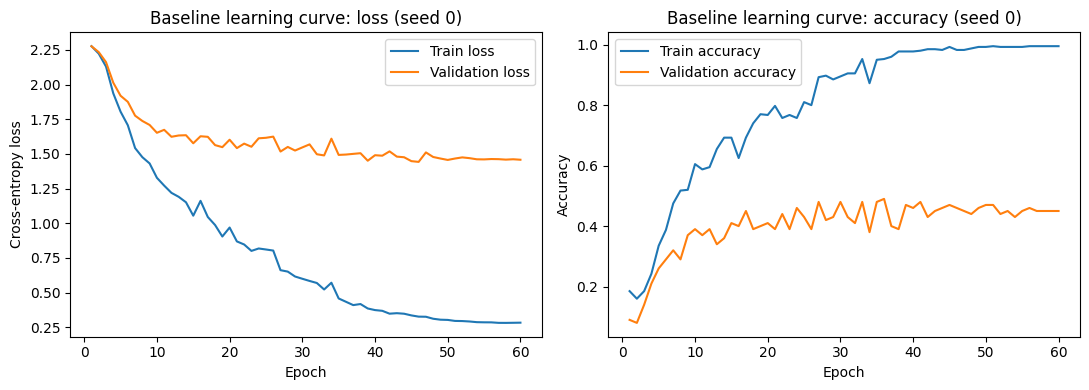

In [18]:
# Ye cell seed 0 par baseline (bina augmentation) chalata hai aur sirf train/val result aur learning curves dikhata hai

import time
t0 = time.time()
m0, h0, best_ep = train_model(seed=0, aug_fn=None)
print("time (sec):", round(time.time() - t0, 1))
print("best epoch:", best_ep)
print("final train acc:", round(h0["train_acc"][-1], 3))
print("best val acc:  ", round(max(h0["val_acc"]), 3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ep_axis = range(1, len(h0["train_acc"]) + 1)
axes[0].plot(ep_axis, h0["train_loss"], label="Train loss")
axes[0].plot(ep_axis, h0["val_loss"], label="Validation loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].set_title("Baseline learning curve: loss (seed 0)")
axes[0].legend()
axes[1].plot(ep_axis, h0["train_acc"], label="Train accuracy")
axes[1].plot(ep_axis, h0["val_acc"], label="Validation accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Baseline learning curve: accuracy (seed 0)")
axes[1].legend()
plt.tight_layout()
plt.show()

In [19]:
# Ye cell ek config ko 3 seeds par train karta hai aur har seed ki train/val/clean/shifted accuracy return karta hai (ablation mein bhi reuse hoga)

def run_config(name, seeds=(0, 1, 2), **kwargs):
    rows, hists = [], []
    for s in seeds:
        model, hist, best_ep = train_model(seed=s, **kwargs)
        tr, _ = evaluate(model, X_tr, Y_tr)
        va, _ = evaluate(model, X_va, Y_va)
        cl, _ = evaluate(model, X_clean, Y_clean)
        sh, _ = evaluate(model, X_shifted, Y_shifted)
        rows.append({"seed": s, "best_epoch": best_ep, "train": tr, "val": va, "clean": cl, "shifted": sh})
        hists.append(hist)
        print(f"[{name}] seed {s}: train {tr:.3f} | val {va:.3f} | clean {cl:.3f} | shifted {sh:.3f} | best epoch {best_ep}")
    return rows, hists

In [20]:
# Ye cell baseline (no augmentation) ko seeds 0,1,2 par chalata hai aur mean ± std summary print karta hai

base_rows, base_hists = run_config("Baseline", aug_fn=None)

def summarize(rows, keys=("train", "val", "clean", "shifted")):
    out = {}
    for k in keys:
        v = np.array([r[k] for r in rows]) * 100
        out[k] = (v.mean(), v.std())
    return out

base_sum = summarize(base_rows)
print()
for k, (m, s) in base_sum.items():
    print(f"{k:8s}: {m:.2f} ± {s:.2f} %")

[Baseline] seed 0: train 0.953 | val 0.490 | clean 0.422 | shifted 0.158 | best epoch 35
[Baseline] seed 1: train 0.985 | val 0.490 | clean 0.433 | shifted 0.171 | best epoch 50
[Baseline] seed 2: train 0.983 | val 0.470 | clean 0.435 | shifted 0.176 | best epoch 58

train   : 97.33 ± 1.48 %
val     : 48.33 ± 0.94 %
clean   : 43.00 ± 0.60 %
shifted : 16.83 ± 0.79 %


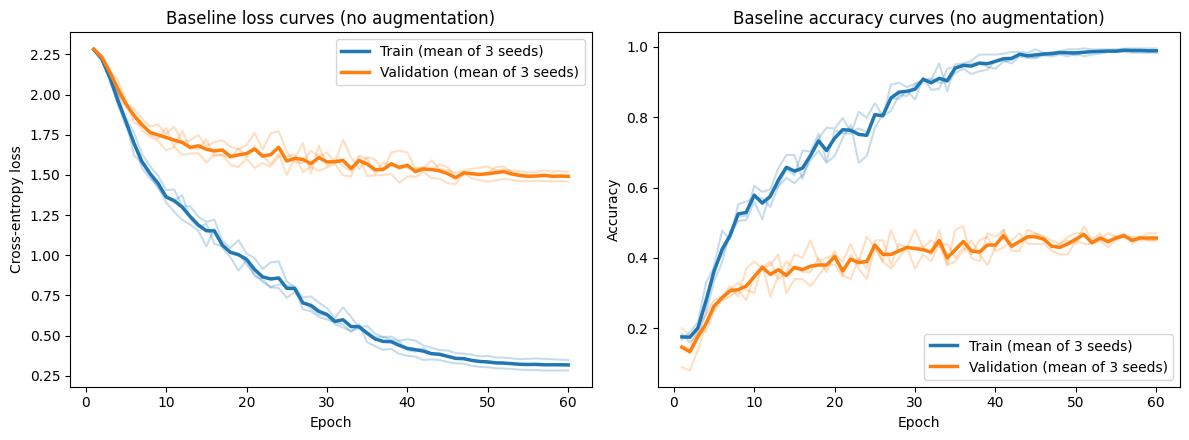

In [21]:
# Ye cell baseline ke teeno seeds ke loss/accuracy curves aur unka mean plot karta hai (Part A ka required plot)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ep_axis = np.arange(1, 61)

for ax, (tk, vk, ylab, ttl) in zip(axes, [("train_loss", "val_loss", "Cross-entropy loss", "Baseline loss curves"),
                                           ("train_acc", "val_acc", "Accuracy", "Baseline accuracy curves")]):
    for h in base_hists:
        ax.plot(ep_axis, h[tk], color="tab:blue", alpha=0.25)
        ax.plot(ep_axis, h[vk], color="tab:orange", alpha=0.25)
    ax.plot(ep_axis, np.mean([h[tk] for h in base_hists], axis=0), color="tab:blue", lw=2.5, label="Train (mean of 3 seeds)")
    ax.plot(ep_axis, np.mean([h[vk] for h in base_hists], axis=0), color="tab:orange", lw=2.5, label="Validation (mean of 3 seeds)")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylab)
    ax.set_title(ttl + " (no augmentation)")
    ax.legend()
plt.tight_layout()
plt.show()

In [22]:
# Ye cell geometric (crop, flip, rotation) aur photometric (jitter, blur, noise, grayscale) augmentation functions banata hai, sab GPU par batch-wise

def random_crop_pad(x, pad=4):
    n, c, h, w = x.shape
    xp = F.pad(x, (pad, pad, pad, pad), mode="reflect")
    ys = torch.randint(0, 2 * pad + 1, (n,), device=x.device)
    xs = torch.randint(0, 2 * pad + 1, (n,), device=x.device)
    out = torch.empty_like(x)
    for i in range(n):
        out[i] = xp[i, :, ys[i]:ys[i] + h, xs[i]:xs[i] + w]
    return out

def random_hflip(x, p=0.5):
    mask = torch.rand(x.shape[0], device=x.device) < p
    out = x.clone()
    out[mask] = out[mask].flip(3)
    return out

def random_rotate(x, max_deg=25.0):
    n = x.shape[0]
    ang = (torch.rand(n, device=x.device) * 2 - 1) * max_deg * math.pi / 180.0
    cos, sin = torch.cos(ang), torch.sin(ang)
    theta = torch.zeros(n, 2, 3, device=x.device)
    theta[:, 0, 0], theta[:, 0, 1] = cos, -sin
    theta[:, 1, 0], theta[:, 1, 1] = sin, cos
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    return F.grid_sample(x, grid, padding_mode="zeros", align_corners=False)

def color_jitter(x, b=0.4, c=0.4, s=0.4):
    n = x.shape[0]
    rb = 1 + (torch.rand(n, 1, 1, 1, device=x.device) * 2 - 1) * b
    rc = 1 + (torch.rand(n, 1, 1, 1, device=x.device) * 2 - 1) * c
    rs = 1 + (torch.rand(n, 1, 1, 1, device=x.device) * 2 - 1) * s
    x = x * rb
    mean = x.mean(dim=(1, 2, 3), keepdim=True)
    x = (x - mean) * rc + mean
    gray = (0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3])
    x = (x - gray) * rs + gray
    return x.clamp(0, 1)

def random_grayscale(x, p=0.2):
    mask = (torch.rand(x.shape[0], device=x.device) < p).view(-1, 1, 1, 1)
    gray = (0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3]).repeat(1, 3, 1, 1)
    return torch.where(mask, gray, x)

def random_blur(x, p=0.3):
    k = torch.tensor([1., 2., 1.], device=x.device)
    k = (k[:, None] * k[None, :]) / 16.0
    k = k.view(1, 1, 3, 3).repeat(3, 1, 1, 1)
    blurred = F.conv2d(F.pad(x, (1, 1, 1, 1), mode="reflect"), k, groups=3)
    mask = (torch.rand(x.shape[0], device=x.device) < p).view(-1, 1, 1, 1)
    return torch.where(mask, blurred, x)

def random_noise(x, max_std=0.06, p=0.5):
    std = torch.rand(x.shape[0], 1, 1, 1, device=x.device) * max_std
    mask = (torch.rand(x.shape[0], device=x.device) < p).view(-1, 1, 1, 1)
    return torch.where(mask, (x + torch.randn_like(x) * std).clamp(0, 1), x)

In [23]:
# Ye cell Cutout aur Mixup banata hai, phir geometric/photometric/cutout ko jodne wale builder functions (ablation configs ke liye)

def cutout(x, area_frac=0.25, p=0.7):
    n, _, h, w = x.shape
    side = int(round(math.sqrt(area_frac * h * w)))
    out = x.clone()
    apply = torch.rand(n, device=x.device) < p
    ys = torch.randint(0, h - side + 1, (n,), device=x.device)
    xs = torch.randint(0, w - side + 1, (n,), device=x.device)
    for i in range(n):
        if apply[i]:
            out[i, :, ys[i]:ys[i] + side, xs[i]:xs[i] + side] = 0.0
    return out

def geometric(x):
    return random_rotate(random_hflip(random_crop_pad(x)), 25.0)

def photometric(x):
    return random_noise(random_blur(random_grayscale(color_jitter(x))))

def geo_photo(x):
    return photometric(geometric(x))

def geo_photo_cutout(x):
    return cutout(geo_photo(x))

print("augmentation functions ready")

augmentation functions ready


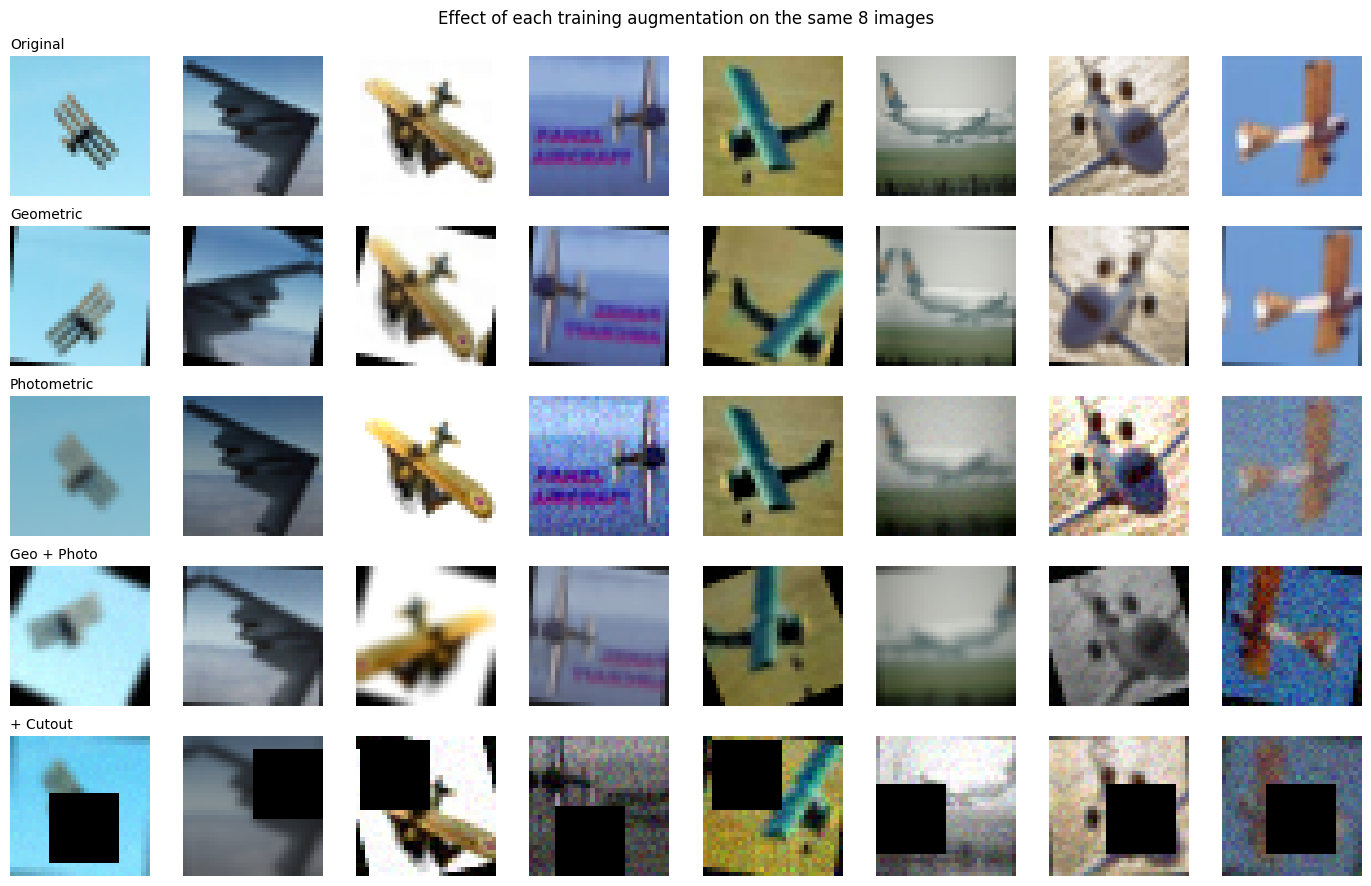

In [24]:
# Ye cell ek hi 8 training images par har augmentation ka asar dikhata hai taake check ho sake ke sab sahi kaam kar rahe hain

set_seed(7)
sample = X_tr[:8]
rows = [("Original", sample), ("Geometric", geometric(sample)), ("Photometric", photometric(sample)),
        ("Geo + Photo", geo_photo(sample)), ("+ Cutout", geo_photo_cutout(sample))]

fig, axes = plt.subplots(len(rows), 8, figsize=(14, 9))
for r, (name, imgs) in enumerate(rows):
    for j in range(8):
        axes[r, j].imshow(imgs[j].permute(1, 2, 0).clamp(0, 1).cpu().numpy())
        axes[r, j].axis("off")
    axes[r, 0].set_title(name, loc="left", fontsize=10)
fig.suptitle("Effect of each training augmentation on the same 8 images")
plt.tight_layout()
plt.show()

In [25]:
# Ye cell train_model ko update karta hai: ab mixup_alpha option bhi hai (0 matlab mixup band), baqi sab pehle jaisa

def train_model(seed, aug_fn=None, epochs=60, batch_size=64, lr=2e-3,
                weight_decay=5e-4, smoothing=0.0, dropout=0.4, mixup_alpha=0.0):
    set_seed(seed)
    model = InceptionNet(train_mean, train_std, dropout=dropout).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)

    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best = {"val_acc": -1.0, "val_loss": 1e9, "epoch": -1, "state": None}
    n = X_tr.shape[0]

    for ep in range(epochs):
        model.train()
        perm = torch.randperm(n, device=device)
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            xb, yb = X_tr[idx], Y_tr[idx]
            if aug_fn is not None:
                xb = aug_fn(xb)
            if mixup_alpha > 0:
                lam = float(np.random.beta(mixup_alpha, mixup_alpha))
                p2 = torch.randperm(xb.shape[0], device=device)
                xb = lam * xb + (1 - lam) * xb[p2]
                logits = model(xb)
                loss = (lam * F.cross_entropy(logits, yb, label_smoothing=smoothing)
                        + (1 - lam) * F.cross_entropy(logits, yb[p2], label_smoothing=smoothing))
            else:
                loss = F.cross_entropy(model(xb), yb, label_smoothing=smoothing)
            opt.zero_grad()
            loss.backward()
            opt.step()
        sched.step()

        tr_acc, tr_loss = evaluate(model, X_tr, Y_tr)
        va_acc, va_loss = evaluate(model, X_va, Y_va)
        hist["train_loss"].append(tr_loss)
        hist["train_acc"].append(tr_acc)
        hist["val_loss"].append(va_loss)
        hist["val_acc"].append(va_acc)

        if va_acc > best["val_acc"] or (va_acc == best["val_acc"] and va_loss < best["val_loss"]):
            best.update(val_acc=va_acc, val_loss=va_loss, epoch=ep,
                        state=copy.deepcopy(model.state_dict()))

    model.load_state_dict(best["state"])
    return model, hist, best["epoch"]

In [26]:
# Ye cell ablation ke 6 configurations (No aug se Mixup+smoothing tak) ko seeds 0,1,2 par chalata hai aur results store karta hai

configs = {
    "No augmentation": dict(aug_fn=None),
    "Geometric only": dict(aug_fn=geometric),
    "Photometric only": dict(aug_fn=photometric),
    "Geometric + photometric": dict(aug_fn=geo_photo),
    "+ Cutout": dict(aug_fn=geo_photo_cutout),
    "+ Mixup + label smoothing": dict(aug_fn=geo_photo_cutout, mixup_alpha=0.2, smoothing=0.1),
}

ablation = {}
for name, kw in configs.items():
    rows, hists = run_config(name, **kw)
    ablation[name] = {"rows": rows, "hists": hists}
    print()

[No augmentation] seed 0: train 0.953 | val 0.490 | clean 0.422 | shifted 0.158 | best epoch 35
[No augmentation] seed 1: train 0.985 | val 0.490 | clean 0.433 | shifted 0.171 | best epoch 50
[No augmentation] seed 2: train 0.983 | val 0.470 | clean 0.435 | shifted 0.176 | best epoch 58

[Geometric only] seed 0: train 0.670 | val 0.450 | clean 0.402 | shifted 0.160 | best epoch 46
[Geometric only] seed 1: train 0.682 | val 0.430 | clean 0.401 | shifted 0.195 | best epoch 59
[Geometric only] seed 2: train 0.650 | val 0.410 | clean 0.393 | shifted 0.184 | best epoch 33

[Photometric only] seed 0: train 0.780 | val 0.560 | clean 0.436 | shifted 0.191 | best epoch 52
[Photometric only] seed 1: train 0.700 | val 0.450 | clean 0.410 | shifted 0.193 | best epoch 44
[Photometric only] seed 2: train 0.745 | val 0.520 | clean 0.423 | shifted 0.195 | best epoch 59

[Geometric + photometric] seed 0: train 0.515 | val 0.450 | clean 0.373 | shifted 0.190 | best epoch 49
[Geometric + photometric] see

,Configuration,Val Acc,Clean Test,Shifted Test
0,No augmentation,48.33 ± 0.94,43.00 ± 0.60,16.83 ± 0.79
1,Geometric only,43.00 ± 1.63,39.86 ± 0.38,17.98 ± 1.44
2,Photometric only,51.00 ± 4.55,42.30 ± 1.08,19.28 ± 0.17
3,Geometric + photometric,42.67 ± 2.05,36.42 ± 0.99,19.44 ± 0.29
4,+ Cutout,36.00 ± 0.82,34.36 ± 0.49,23.18 ± 1.06
5,+ Mixup + label smoothing,36.00 ± 0.82,33.02 ± 1.67,21.56 ± 1.73


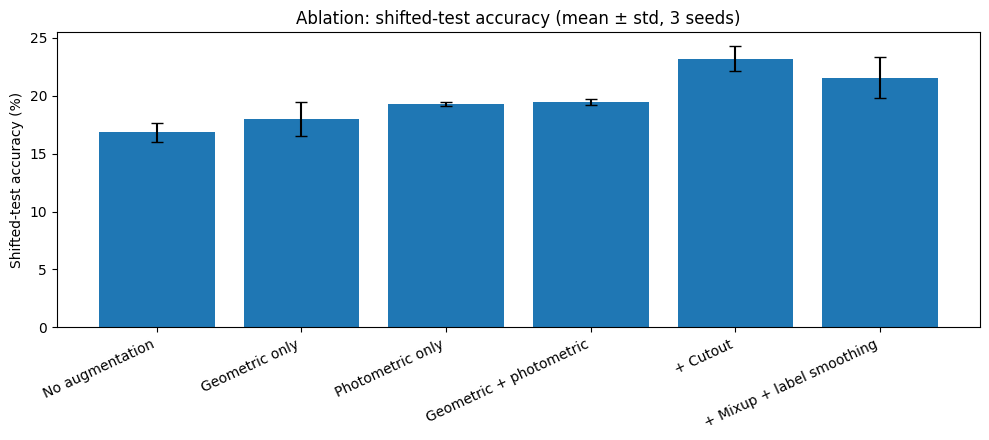

In [27]:
# Ye cell ablation results ka mean ± std table banata hai aur shifted-test accuracy ka bar chart plot karta hai

import pandas as pd

table = []
for name, d in ablation.items():
    s = summarize(d["rows"])
    table.append({
        "Configuration": name,
        "Val Acc": f"{s['val'][0]:.2f} ± {s['val'][1]:.2f}",
        "Clean Test": f"{s['clean'][0]:.2f} ± {s['clean'][1]:.2f}",
        "Shifted Test": f"{s['shifted'][0]:.2f} ± {s['shifted'][1]:.2f}",
    })
abl_df = pd.DataFrame(table)
display(abl_df)

names = list(ablation.keys())
means = [summarize(ablation[n]["rows"])["shifted"][0] for n in names]
stds = [summarize(ablation[n]["rows"])["shifted"][1] for n in names]

plt.figure(figsize=(10, 4.5))
plt.bar(range(len(names)), means, yerr=stds, capsize=4, color="tab:blue")
plt.xticks(range(len(names)), names, rotation=25, ha="right")
plt.ylabel("Shifted-test accuracy (%)")
plt.title("Ablation: shifted-test accuracy (mean ± std, 3 seeds)")
plt.tight_layout()
plt.show()

In [28]:
# Ye cell wide model banata hai (channels 2.5x) taake augmentation ke saath underfit na ho; param count check karta hai

class InceptionNetWide(nn.Module):
    def __init__(self, mean, std, num_classes=10, dropout=0.4, w=2.5):
        super().__init__()
        s = lambda c: int(round(c * w))
        self.register_buffer("mean", mean.clone())
        self.register_buffer("std", std.clone())
        self.stem = ConvBNReLU(3, s(32), 3)
        self.inc1 = InceptionBlock(s(32), s(16), s(16), s(24), s(8), s(8), s(8))
        self.inc2 = InceptionBlock(s(16) + s(24) + s(8) + s(8), s(32), s(24), s(48), s(8), s(16), s(16))
        self.pool = nn.MaxPool2d(2)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(s(32) + s(48) + s(16) + s(16), num_classes)

    def forward(self, x):
        x = (x - self.mean) / self.std
        x = self.pool(self.stem(x))
        x = self.pool(self.inc1(x))
        x = self.pool(self.inc2(x))
        return self.fc(self.drop(x.mean(dim=(2, 3))))

m = InceptionNetWide(train_mean, train_std).to(device)
print("wide model parameters:", count_params(m), "| within limit:", count_params(m) <= 1_000_000)

wide model parameters: 160250 | within limit: True


In [29]:
# Ye cell train_model ko update karta hai taake model class (narrow ya wide) chuni ja sake, aur milder augmentation functions banata hai

def train_model(seed, aug_fn=None, epochs=60, batch_size=64, lr=2e-3,
                weight_decay=5e-4, smoothing=0.0, dropout=0.4, mixup_alpha=0.0,
                model_cls=InceptionNet):
    set_seed(seed)
    model = model_cls(train_mean, train_std, dropout=dropout).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)

    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best = {"val_acc": -1.0, "val_loss": 1e9, "epoch": -1, "state": None}
    n = X_tr.shape[0]

    for ep in range(epochs):
        model.train()
        perm = torch.randperm(n, device=device)
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            xb, yb = X_tr[idx], Y_tr[idx]
            if aug_fn is not None:
                xb = aug_fn(xb)
            if mixup_alpha > 0:
                lam = float(np.random.beta(mixup_alpha, mixup_alpha))
                p2 = torch.randperm(xb.shape[0], device=device)
                xb = lam * xb + (1 - lam) * xb[p2]
                logits = model(xb)
                loss = (lam * F.cross_entropy(logits, yb, label_smoothing=smoothing)
                        + (1 - lam) * F.cross_entropy(logits, yb[p2], label_smoothing=smoothing))
            else:
                loss = F.cross_entropy(model(xb), yb, label_smoothing=smoothing)
            opt.zero_grad()
            loss.backward()
            opt.step()
        sched.step()

        tr_acc, tr_loss = evaluate(model, X_tr, Y_tr)
        va_acc, va_loss = evaluate(model, X_va, Y_va)
        hist["train_loss"].append(tr_loss)
        hist["train_acc"].append(tr_acc)
        hist["val_loss"].append(va_loss)
        hist["val_acc"].append(va_acc)

        if va_acc > best["val_acc"] or (va_acc == best["val_acc"] and va_loss < best["val_loss"]):
            best.update(val_acc=va_acc, val_loss=va_loss, epoch=ep,
                        state=copy.deepcopy(model.state_dict()))

    model.load_state_dict(best["state"])
    return model, hist, best["epoch"]


def mild_geometric(x):
    return random_rotate(random_hflip(random_crop_pad(x, pad=3)), 15.0)

def mild_photometric(x):
    return random_noise(random_blur(random_grayscale(color_jitter(x, 0.3, 0.3, 0.3), p=0.15), p=0.2), max_std=0.04, p=0.4)

def mild_all(x):
    return cutout(mild_photometric(mild_geometric(x)), area_frac=0.2, p=0.5)

print("ready")

ready


In [30]:
# Ye cell options A-D ko 3 seeds par chalata hai aur SIRF train/validation accuracy report karta hai (test ko touch nahi karta)

def val_only(name, seeds=(0, 1, 2), **kw):
    trs, vas = [], []
    for s in seeds:
        model, hist, ep = train_model(seed=s, **kw)
        trs.append(evaluate(model, X_tr, Y_tr)[0])
        vas.append(evaluate(model, X_va, Y_va)[0])
    print(f"{name:34s} train {np.mean(trs)*100:5.1f} | val {np.mean(vas)*100:5.1f} ± {np.std(vas)*100:.1f}")
    return np.mean(vas)

val_only("A narrow + current aug", aug_fn=geo_photo_cutout)
val_only("B wide + current aug", aug_fn=geo_photo_cutout, model_cls=InceptionNetWide)
val_only("C wide + milder aug", aug_fn=mild_all, model_cls=InceptionNetWide)
val_only("D wide + milder + mixup + smoothing", aug_fn=mild_all, model_cls=InceptionNetWide, mixup_alpha=0.2, smoothing=0.1)

A narrow + current aug             train  43.8 | val  36.0 ± 0.8
B wide + current aug               train  52.5 | val  39.7 ± 0.9
C wide + milder aug                train  64.2 | val  44.0 ± 0.8
D wide + milder + mixup + smoothing train  60.6 | val  45.7 ± 2.1


np.float64(0.4566666666666667)

In [31]:
# Ye cell final configuration (wide model + mild augmentation + mixup + label smoothing) ko seeds 0,1,2 par chalata hai aur final table row banata hai

final_kwargs = dict(aug_fn=mild_all, model_cls=InceptionNetWide, mixup_alpha=0.2, smoothing=0.1)
final_rows, final_hists = run_config("Final model", **final_kwargs)

final_sum = summarize(final_rows)
print()
for k, (m, s) in final_sum.items():
    print(f"{k:8s}: {m:.2f} ± {s:.2f} %")

[Final model] seed 0: train 0.585 | val 0.460 | clean 0.395 | shifted 0.239 | best epoch 30
[Final model] seed 1: train 0.655 | val 0.430 | clean 0.425 | shifted 0.255 | best epoch 41
[Final model] seed 2: train 0.578 | val 0.480 | clean 0.406 | shifted 0.248 | best epoch 28

train   : 60.58 ± 3.49 %
val     : 45.67 ± 2.05 %
clean   : 40.87 ± 1.24 %
shifted : 24.72 ± 0.64 %


In [32]:
# Ye cell final model ko ablation table mein jodta hai aur saari 7 rows ka table dikhata hai

ablation["Final model (wide + mild aug + mixup + smoothing)"] = {"rows": final_rows, "hists": final_hists}

table = []
for name, d in ablation.items():
    s = summarize(d["rows"])
    table.append({
        "Configuration": name,
        "Val Acc": f"{s['val'][0]:.2f} ± {s['val'][1]:.2f}",
        "Clean Test": f"{s['clean'][0]:.2f} ± {s['clean'][1]:.2f}",
        "Shifted Test": f"{s['shifted'][0]:.2f} ± {s['shifted'][1]:.2f}",
    })
display(pd.DataFrame(table))

,Configuration,Val Acc,Clean Test,Shifted Test
0,No augmentation,48.33 ± 0.94,43.00 ± 0.60,16.83 ± 0.79
1,Geometric only,43.00 ± 1.63,39.86 ± 0.38,17.98 ± 1.44
2,Photometric only,51.00 ± 4.55,42.30 ± 1.08,19.28 ± 0.17
3,Geometric + photometric,42.67 ± 2.05,36.42 ± 0.99,19.44 ± 0.29
4,+ Cutout,36.00 ± 0.82,34.36 ± 0.49,23.18 ± 1.06
5,+ Mixup + label smoothing,36.00 ± 0.82,33.02 ± 1.67,21.56 ± 1.73
6,Final model (wide + mild aug + mixup + smoothing),45.67 ± 2.05,40.87 ± 1.24,24.72 ± 0.64


In [33]:
# Ye cell final model ko seed 0 par dobara train karta hai aur shifted/clean test par predictions nikalta hai (error analysis ke liye)

@torch.no_grad()
def predict(model, X, batch_size=1000):
    model.eval()
    return torch.cat([model(X[i:i + batch_size]).argmax(1) for i in range(0, X.shape[0], batch_size)])

final_model, _, _ = train_model(seed=0, **final_kwargs)
pred_shift = predict(final_model, X_shifted).cpu().numpy()
pred_clean = predict(final_model, X_clean).cpu().numpy()
yt = Y_clean.cpu().numpy()

print("shifted acc:", (pred_shift == yt).mean())
print("clean acc:  ", (pred_clean == yt).mean())

shifted acc: 0.2391
clean acc:   0.3954


airplane   :  12.5 %
automobile :  13.7 %
bird       :  37.9 %
cat        :  30.8 %
deer       :  10.0 %
dog        :  15.8 %
frog       :  23.2 %
horse      :  16.0 %
ship       :  42.4 %
truck      :  36.8 %


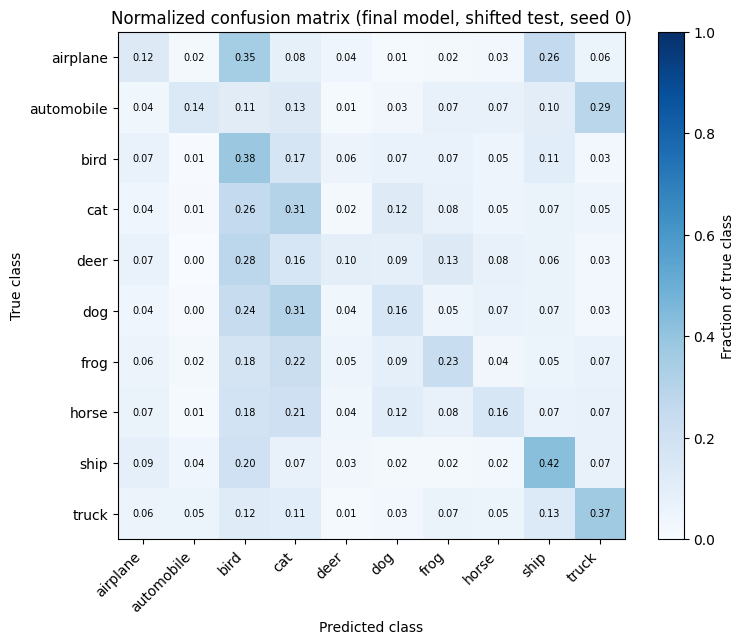


Most confused (true -> predicted):
  airplane -> bird: 35.3 %
  dog -> cat: 30.7 %
  automobile -> truck: 28.7 %
  deer -> bird: 28.1 %
  airplane -> ship: 25.6 %


In [34]:
# Ye cell shifted test par har class ki accuracy print karta hai aur normalized confusion matrix plot karta hai

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(yt, pred_shift, labels=range(10))
cm_norm = cm / cm.sum(axis=1, keepdims=True)

for c in range(10):
    print(f"{CLASS_NAMES[c]:11s}: {cm_norm[c, c]*100:5.1f} %")

plt.figure(figsize=(8, 6.5))
plt.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
plt.colorbar(label="Fraction of true class")
plt.xticks(range(10), CLASS_NAMES, rotation=45, ha="right")
plt.yticks(range(10), CLASS_NAMES)
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Normalized confusion matrix (final model, shifted test, seed 0)")
for i in range(10):
    for j in range(10):
        plt.text(j, i, f"{cm_norm[i, j]:.2f}", ha="center", va="center",
                 color="white" if cm_norm[i, j] > 0.5 else "black", fontsize=7)
plt.tight_layout()
plt.show()

off = cm_norm.copy()
np.fill_diagonal(off, 0)
top = np.dstack(np.unravel_index(np.argsort(-off.ravel())[:5], off.shape))[0]
print("\nMost confused (true -> predicted):")
for i, j in top:
    print(f"  {CLASS_NAMES[i]} -> {CLASS_NAMES[j]}: {off[i, j]*100:.1f} %")

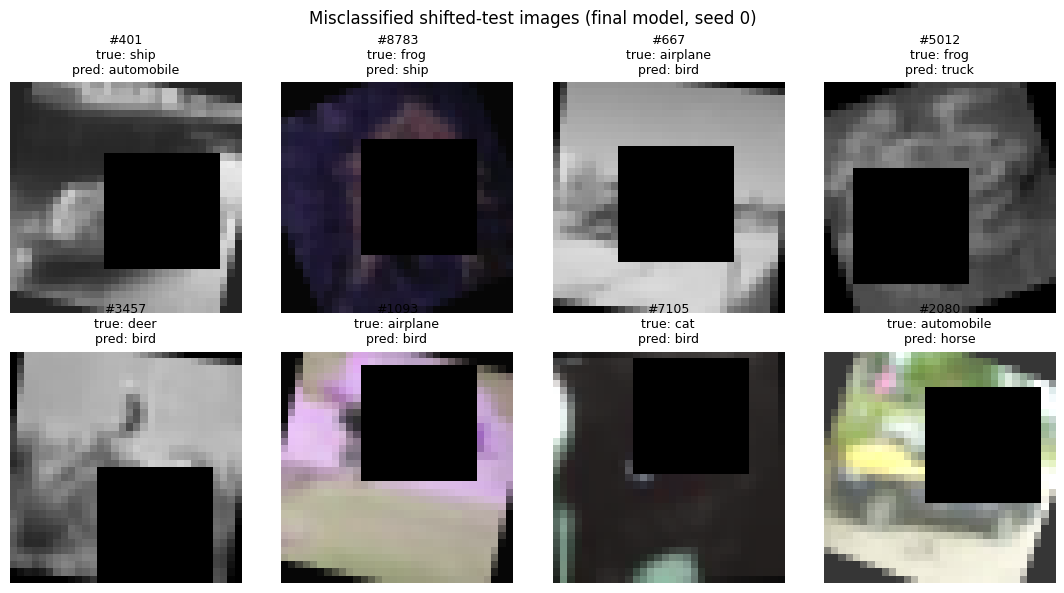

indices: [401, 8783, 667, 5012, 3457, 1093, 7105, 2080]


In [35]:
# Ye cell shifted test ki 8 galat predict hui images dikhata hai (true aur predicted label ke saath) taake visual wajah likhi ja sake

wrong = np.where(pred_shift != yt)[0]
rs = np.random.RandomState(0)
pick = rs.choice(wrong, 8, replace=False)

fig, axes = plt.subplots(2, 4, figsize=(11, 6))
for ax, k in zip(axes.ravel(), pick):
    ax.imshow(X_shifted[k].permute(1, 2, 0).cpu().numpy())
    ax.set_title(f"#{k}\ntrue: {CLASS_NAMES[yt[k]]}\npred: {CLASS_NAMES[pred_shift[k]]}", fontsize=9)
    ax.axis("off")
fig.suptitle("Misclassified shifted-test images (final model, seed 0)")
plt.tight_layout()
plt.show()
print("indices:", pick.tolist())

In [36]:
# Ye cell sirf hidden corruption (channel swap/grayscale) clean test par lagakar accuracy compare karta hai (final model vs baseline)

gen = torch.Generator(device=device)
gen.manual_seed(123)
X_hidden = hidden_corruption(X_clean, gen)

base_model, _, _ = train_model(seed=0, aug_fn=None)
print("Hidden-corruption only | baseline :", round(evaluate(base_model, X_hidden, Y_clean)[0] * 100, 2))
print("Hidden-corruption only | final    :", round(evaluate(final_model, X_hidden, Y_clean)[0] * 100, 2))
print("Clean (no corruption)  | baseline :", round(evaluate(base_model, X_clean, Y_clean)[0] * 100, 2))
print("Clean (no corruption)  | final    :", round(evaluate(final_model, X_clean, Y_clean)[0] * 100, 2))

Hidden-corruption only | baseline : 35.73
Hidden-corruption only | final    : 31.35
Clean (no corruption)  | baseline : 42.16
Clean (no corruption)  | final    : 39.54


In [37]:
# Ye cell hidden corruption ko do hisson mein todta hai (sirf grayscale, sirf channel swap) aur dekhta hai ke bird ki prediction clean vs shifted par kitni badalti hai

def gray_all(x):
    return (0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3]).repeat(1, 3, 1, 1)

def swap_all(x, gen):
    perms = torch.tensor([[2, 1, 0], [1, 2, 0], [0, 2, 1]], device=x.device)
    pick = torch.randint(0, 3, (x.shape[0],), generator=gen, device=x.device)
    return torch.stack([x[i][perms[pick[i]]] for i in range(x.shape[0])])

gen2 = torch.Generator(device=device)
gen2.manual_seed(321)
X_gray = gray_all(X_clean)
X_swap = swap_all(X_clean, gen2)

for name, m in [("baseline", base_model), ("final", final_model)]:
    c = evaluate(m, X_clean, Y_clean)[0] * 100
    g = evaluate(m, X_gray, Y_clean)[0] * 100
    s = evaluate(m, X_swap, Y_clean)[0] * 100
    print(f"{name:8s} | clean {c:5.2f} | grayscale only {g:5.2f} | channel swap only {s:5.2f}")

share_clean = np.bincount(pred_clean, minlength=10) / len(pred_clean) * 100
share_shift = np.bincount(pred_shift, minlength=10) / len(pred_shift) * 100
print("\nShare of predictions per class (final model, seed 0). Fair share = 10 %")
print(f"{'class':11s} {'clean':>7s} {'shifted':>8s}")
for c in range(10):
    print(f"{CLASS_NAMES[c]:11s} {share_clean[c]:7.1f} {share_shift[c]:8.1f}")

baseline | clean 42.16 | grayscale only 36.37 | channel swap only 28.33
final    | clean 39.54 | grayscale only 28.81 | channel swap only 24.70

Share of predictions per class (final model, seed 0). Fair share = 10 %
class         clean  shifted
airplane        4.2      6.6
automobile      5.5      3.1
bird            2.9     23.1
cat            15.0     17.7
deer            7.0      4.0
dog             6.1      7.4
frog           12.0      8.1
horse          15.0      6.1
ship           13.1     13.5
truck          19.0     10.5


In [38]:
# Ye cell sirf occlusion (black box) clean test par lagakar dekhta hai ke bird ki prediction share kitni badalti hai (bird sink ka sabab check)

gen3 = torch.Generator(device=device)
gen3.manual_seed(5)
X_occ = occlude(X_clean, 0.25, gen3)
pred_occ = predict(final_model, X_occ).cpu().numpy()
share_occ = np.bincount(pred_occ, minlength=10) / len(pred_occ) * 100
print("occlusion-only accuracy:", round((pred_occ == yt).mean() * 100, 2))
print("bird share with occlusion only:", round(share_occ[2], 1), "% (clean was 2.9 %, shifted was 23.1 %)")

occlusion-only accuracy: 37.55
bird share with occlusion only: 10.5 % (clean was 2.9 %, shifted was 23.1 %)


In [39]:
# Ye cell TTA chalata hai: 8 versions (identity, flip, 3 chhote shifts, aur unke flips) ka softmax average, phir accuracy aur inference time compare karta hai

import time

def shift_img(x, dx, dy):
    p = 2
    xp = F.pad(x, (p, p, p, p), mode="reflect")
    return xp[:, :, p + dy:p + dy + x.shape[2], p + dx:p + dx + x.shape[3]]

tta_views = [
    lambda x: x,
    lambda x: x.flip(3),
    lambda x: shift_img(x, 2, 0),
    lambda x: shift_img(x, -2, 0),
    lambda x: shift_img(x, 0, 2),
    lambda x: shift_img(x, 0, -2),
    lambda x: shift_img(x, 2, 2).flip(3),
    lambda x: shift_img(x, -2, -2).flip(3),
]

@torch.no_grad()
def predict_tta(model, X, views, batch_size=1000):
    model.eval()
    out = []
    for i in range(0, X.shape[0], batch_size):
        xb = X[i:i + batch_size]
        prob = sum(F.softmax(model(v(xb)), dim=1) for v in views) / len(views)
        out.append(prob.argmax(1))
    return torch.cat(out)

def timed(fn):
    torch.cuda.synchronize()
    t = time.time()
    r = fn()
    torch.cuda.synchronize()
    return r, time.time() - t

for name, X in [("clean", X_clean), ("shifted", X_shifted)]:
    p1, t1 = timed(lambda: predict(final_model, X))
    pn, tn = timed(lambda: predict_tta(final_model, X, tta_views))
    a1 = (p1 == Y_clean).float().mean().item() * 100
    an = (pn == Y_clean).float().mean().item() * 100
    print(f"{name:8s} | no TTA {a1:5.2f} | TTA(N={len(tta_views)}) {an:5.2f} | change {an - a1:+.2f} | time {t1:.3f}s -> {tn:.3f}s ({tn / t1:.1f}x)")

clean    | no TTA 39.54 | TTA(N=8) 39.76 | change +0.22 | time 0.408s -> 3.236s (7.9x)
shifted  | no TTA 23.91 | TTA(N=8) 24.53 | change +0.62 | time 0.402s -> 3.253s (8.1x)
